## Practical 12: Movie Review Sentiment Analysis

### Aim
Tokenize reviews, remove stop words, vectorize counts and classify positive or negative sentiment.

### Model
CountVectorizer + SVM

### Data
80 original short teaching reviews, balanced between positive and negative. The corpus is intentionally small and stored locally.

### Theory
CountVectorizer performs word tokenization and stop-word removal. Negation words are retained; unigrams and bigrams feed a linear SVM so phrases such as "not good" remain distinguishable.

### Method
Load or generate data, inspect features and labels, fit preprocessing on training data, train the required model, evaluate and visualize the output. See the implementation for the task-specific split.

### Limitation
Accuracy is below the 0.50 majority baseline on this split. The small corpus is insufficient for reliable sentiment learning; use a larger independent review dataset before drawing performance conclusions.

In [ ]:
# Colab CPU runtime is sufficient. No external dataset download is needed.
%pip -q install 'scikit-learn>=1.5,<2' 'pandas>=2.2,<4' 'matplotlib>=3.8,<4'


In [1]:
"""Shared imports and evaluation; also embedded in every standalone notebook."""
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
    IsolationForest, GradientBoostingRegressor, AdaBoostRegressor)
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import (TfidfVectorizer,
    CountVectorizer, ENGLISH_STOP_WORDS)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris, load_breast_cancer, load_digits
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error,
    r2_score, silhouette_score, average_precision_score)
SEED = 42
rng = np.random.default_rng(SEED)
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 10})

def plot_save(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def tabular_preprocessor(frame):
    numeric = frame.select_dtypes(include='number').columns.tolist()
    category = frame.select_dtypes(exclude='number').columns.tolist()
    return ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median'),
                                  StandardScaler()), numeric),
        ('category', make_pipeline(SimpleImputer(strategy='most_frequent'),
          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), category)])

def evaluate(model, X, y, name, classification=True, chronological=False):
    # All fitted preprocessing stays inside the model pipeline.
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25,
        random_state=None if chronological else SEED,
        shuffle=not chronological,
        stratify=y if classification and not chronological else None)
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    print(f'Train: {len(ytr)} | Test: {len(yte)} | Features: '
          f'{X.shape[1] if hasattr(X, "shape") and len(X.shape)>1 else "text"}')
    if classification:
        baseline = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr)
        metrics = {'accuracy': accuracy_score(yte, pred),
                   'macro_f1': f1_score(yte, pred, average='macro'),
                   'baseline_accuracy': accuracy_score(yte, baseline.predict(Xte))}
        print(classification_report(yte, pred, digits=3, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(yte, pred, cmap='Blues',
                                                colorbar=False)
        plt.title(name.replace('_', ' '))
        if any(len(str(v)) > 8 for v in np.unique(yte)):
            plt.xticks(rotation=30, ha='right')
    else:
        baseline = DummyRegressor().fit(Xtr, ytr)
        metrics = {'MAE': mean_absolute_error(yte, pred),
                   'RMSE': np.sqrt(mean_squared_error(yte, pred)),
                   'R2': r2_score(yte, pred),
                   'baseline_MAE': mean_absolute_error(yte, baseline.predict(Xte))}
        plt.scatter(yte, pred, alpha=0.6, s=18)
        lo, hi = min(min(yte), min(pred)), max(max(yte), max(pred))
        plt.plot([lo, hi], [lo, hi], 'k--')
        plt.xlabel('Actual target'); plt.ylabel('Predicted target')
        plt.title(name.replace('_', ' '))
    for key, value in metrics.items():
        print(f'{key}: {value:.4f}')
    plot_save(name)
    print('First five held-out predictions:', pred[:5])
    return metrics

def clean_text(text):
    text = re.sub(r'https?://\S+', ' url ', str(text).lower())
    text = re.sub(r'\d+', ' number ', text)
    return ' '.join(re.findall(r'[a-z]+', text))


In [2]:
DATA = Path('data')
DATA.mkdir(exist_ok=True)
(DATA / 'reviews.csv').write_text('text,label\nA wonderful story with excellent acting,positive\nThe film was charming and beautifully directed,positive\nI loved the clever dialogue and warm characters,positive\nAn exciting adventure with a satisfying ending,positive\nThe performances were superb throughout the movie,positive\nA moving story that stayed with me,positive\nBrilliant cinematography made every scene memorable,positive\nThis comedy was funny and full of heart,positive\nThe soundtrack was beautiful and the acting convincing,positive\nA delightful film worth watching again,positive\nAn intelligent script supported by excellent actors,positive\nThe pacing was energetic and the plot engaging,positive\nI enjoyed the emotional depth of the characters,positive\nA powerful performance lifted an already great story,positive\nThe movie was surprisingly original and entertaining,positive\nA lovely family film with a thoughtful message,positive\nThe director created a vivid and wonderful world,positive\nExcellent action scenes and a compelling story,positive\nThe ending was touching and deeply satisfying,positive\nA clever mystery with believable characters,positive\nThe actors delivered warm and memorable performances,positive\nA stunning visual experience with real emotional weight,positive\nI was impressed by the sharp writing,positive\nThe film made me laugh and care about everyone,positive\nA fantastic adaptation with beautiful music,positive\nThe story was absorbing from the opening scene,positive\nA sensitive and honest portrayal of friendship,positive\nThe comedy timing was excellent and natural,positive\nThis was an enjoyable and rewarding cinema experience,positive\nA gripping thriller with brilliant performances,positive\nThe animation was gorgeous and imaginative,positive\nA great cast brought the story to life,positive\nThe film was not boring and kept me engaged,positive\nA hopeful ending made this a pleasant watch,positive\nThe lead actor was superb in a difficult role,positive\nA refreshing story with charming humour,positive\nThe dialogue felt authentic and the direction confident,positive\nA masterful blend of suspense and emotion,positive\nI recommend this wonderful and uplifting movie,positive\nA thoughtful drama with outstanding character development,positive\nA boring story with terrible acting,negative\nThe film was dull and poorly directed,negative\nI hated the awkward dialogue and flat characters,negative\nA tedious adventure with a disappointing ending,negative\nThe performances were weak throughout the movie,negative\nA confusing story that never made sense,negative\nPoor editing made every scene feel endless,negative\nThis comedy was unfunny and painfully predictable,negative\nThe soundtrack was annoying and the acting wooden,negative\nA dreadful film not worth watching again,negative\nA lazy script wasted a talented cast,negative\nThe pacing was slow and the plot uninteresting,negative\nI disliked the shallow portrayal of the characters,negative\nA weak performance ruined an already poor story,negative\nThe movie was painfully repetitive and forgettable,negative\nA noisy family film with an empty message,negative\nThe director created a lifeless and confusing world,negative\nTerrible action scenes and an incoherent story,negative\nThe ending was abrupt and deeply unsatisfying,negative\nA predictable mystery with unbelievable characters,negative\nThe actors delivered stiff and forgettable performances,negative\nAn ugly visual experience with no emotional impact,negative\nI was disappointed by the clumsy writing,negative\nThe film failed to make me laugh or care,negative\nA bad adaptation with irritating music,negative\nThe story was tedious from the opening scene,negative\nA shallow and dishonest portrayal of friendship,negative\nThe comedy timing was awkward and forced,negative\nThis was a frustrating and unrewarding cinema experience,negative\nA dull thriller with terrible performances,negative\nThe animation was crude and uninspired,negative\nA weak cast failed to bring the story to life,negative\nThe film was not good and left me disappointed,negative\nA rushed ending made this an unpleasant watch,negative\nThe lead actor was unconvincing in every scene,negative\nA stale story with childish humour,negative\nThe dialogue felt artificial and the direction careless,negative\nA messy blend of cheap suspense and melodrama,negative\nI cannot recommend this boring and depressing movie,negative\nA pointless drama with poor character development,negative\n', encoding='utf-8')


Example tokens: ['wonderful', 'story', 'excellent', 'acting', 'wonderful story', 'story excellent', 'excellent acting']
Train: 60 | Test: 20 | Features: text
              precision    recall  f1-score   support

    negative      0.200     0.100     0.133        10
    positive      0.400     0.600     0.480        10

    accuracy                          0.350        20
   macro avg      0.300     0.350     0.307        20
weighted avg      0.300     0.350     0.307        20

accuracy: 0.3500
macro_f1: 0.3067
baseline_accuracy: 0.5000
First five held-out predictions: ['negative' 'positive' 'positive' 'positive' 'positive']
New review predictions: ['positive' 'negative']


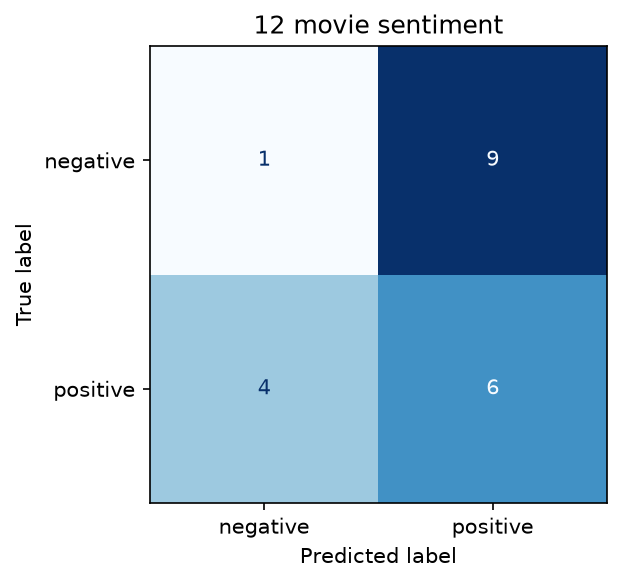

In [3]:
df = pd.read_csv(DATA / 'reviews.csv')
X, y = df.text.map(clean_text), df.label
assert not X.duplicated().any()
stop_words = sorted(set(ENGLISH_STOP_WORDS) - {'not', 'no', 'nor', 'never'})
vectorizer = CountVectorizer(stop_words=stop_words, ngram_range=(1, 2))
print('Example tokens:', vectorizer.build_analyzer()(clean_text(X.iloc[0])))
model = make_pipeline(vectorizer, LinearSVC(C=1.0, random_state=SEED))
metrics = evaluate(model, X, y, '12_movie_sentiment')
examples = ['A wonderful story and excellent acting',
            'A boring story with terrible acting']
print('New review predictions:', model.predict([clean_text(s) for s in examples]))

### Result and conclusion
Measured results: accuracy = 0.3500; macro_f1 = 0.3067; baseline_accuracy = 0.5000. Accuracy is below the 0.50 majority baseline on this split. The small corpus is insufficient for reliable sentiment learning; use a larger independent review dataset before drawing performance conclusions.